<a href="https://colab.research.google.com/github/jinwoolee-eng/predictive-maintenance-ai4i/blob/main/ai4i_predictive_maintenance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 설비 예지보전 데이터 분석 (AI4I 2020)

반도체 식각 설비 PM을 하며 "정해진 주기 대신 설비 상태 데이터로 고장을 미리 알 수 없을까?"라는 궁금증이 생겨, 공개된 예지보전 데이터로 직접 확인해본 프로젝트입니다.

**분석 순서**
1. 데이터 불러오기
2. 고장 현황 파악
3. 고장 유형별 원인 시각화
4. 고장 예측 모델 만들기와 비교

## 1. 데이터 불러오기
UCI AI4I 2020 Predictive Maintenance Dataset (10,000건, 14개 열)

| 열 | 의미 |
|---|---|
| Type | 제품 등급 (L·M·H) |
| Air / Process temperature [K] | 주변 온도, 공정 온도 |
| Rotational speed [rpm] | 회전 속도 |
| Torque [Nm] | 토크 |
| Tool wear [min] | 공구 사용 시간 (부품 사용 시간과 비슷한 개념) |
| Machine failure | 고장 여부 (0 정상, 1 고장) |
| TWF·HDF·PWF·OSF·RNF | 고장 유형 (공구 마모·열 방출·전력·과부하·무작위) |

In [21]:
import pandas as pd

df = pd.read_csv('/ai4i2020.csv')
print(df.shape)
df.head()

(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2. 고장 현황
- 전체 10,000건 중 고장은 **339건 (3.39%)**
- 고장 유형별: 열 방출 115 > 과부하 98 > 전력 95 > 공구 마모 46 > 무작위 19
- 유형별 합계(373)가 고장 건수(339)보다 많음 → 한 번 고장에 원인이 여러 개 겹친 경우가 있음

**주목할 점:** 사용 시간 때문에 생기는 공구 마모 고장은 46건뿐.
→ **가설: 정해진 주기 PM만으로는 막을 수 있는 고장이 일부이고, 상태 데이터를 같이 봐야 한다.**

고장이 3.39%로 드물기 때문에, 무조건 "정상"이라고 해도 정확도가 96%를 넘는다. 따라서 모델 평가는 정확도가 아니라 **고장을 얼마나 잡았는지(recall)**로 봐야 한다.

In [22]:
# 전체 중 고장 난 횟수
print(df['Machine failure'].value_counts())

# 고장 종류별 횟수
print(df[['TWF', 'HDF', 'PWF', 'OSF', 'RNF']].sum())

Machine failure
0    9661
1     339
Name: count, dtype: int64
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64


## 3. 고장 유형별 원인 시각화

### 3-1. 공구 사용 시간과 고장률
- 0 ~ 180분: 고장률 2 ~ 3%로 일정
- 200분 이후 급증 (200 ~ 220분 약 14%, 220 ~ 240분 약 23%)

→ 공구 마모로 인한 위험은 **200분 전후**부터 커진다. 사용 시간 기반 교체 주기는 180~200분이 적절해 보인다.
→ 다만 200분 이전에도 고장이 꾸준히 있음 → 그 고장들은 **마모가 아닌 다른 원인**

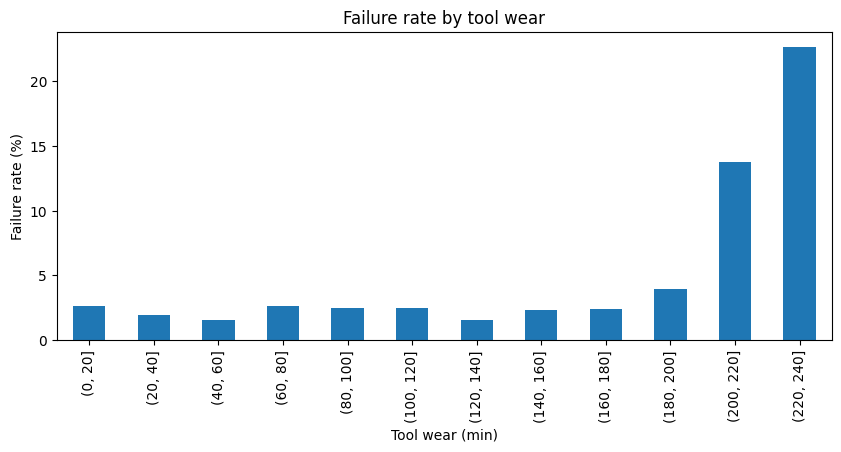

In [23]:
import matplotlib.pyplot as plt

# 공구 사용 시간을 20분 단위로 나누기
df['wear_bin'] = pd.cut(df['Tool wear [min]'], bins=range(0, 260, 20))

# 구간별 고장률(%) 계산
rate = df.groupby('wear_bin', observed=True)['Machine failure'].mean() * 100

# 막대그래프
rate.plot(kind='bar', figsize=(10, 4))
plt.xlabel('Tool wear (min)')
plt.ylabel('Failure rate (%)')
plt.title('Failure rate by tool wear')
plt.show()

### 3-2. 열 방출 고장 (HDF)
- 고장은 **온도 차이가 약 8.6K 아래이면서 회전 속도가 약 1,380rpm 아래**일 때만 발생
- 온도 차이가 작아도 회전이 빠르면 정상, 회전이 느려도 온도 차이가 크면 정상

→ **두 조건을 동시에 봐야** 잡을 수 있는 고장. 각각 따로 알람을 걸면 둘 다 정상 범위라 놓칠 수 있다.
→ 사용 시간과 무관하므로 **주기 PM으로는 막을 수 없다.**

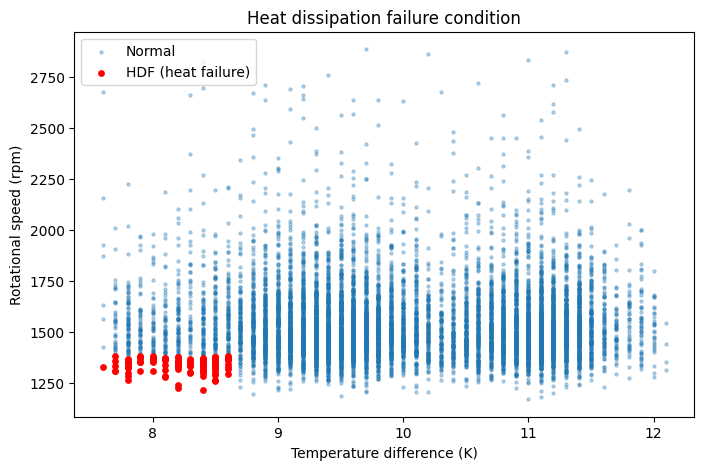

In [24]:
# 공정 온도 - 주변 온도 = 온도 차이
df['temp_diff'] = df['Process temperature [K]'] - df['Air temperature [K]']

normal = df[df['HDF'] == 0]
fail = df[df['HDF'] == 1]

plt.figure(figsize=(8, 5))
plt.scatter(normal['temp_diff'], normal['Rotational speed [rpm]'], s=5, alpha=0.3, label='Normal')
plt.scatter(fail['temp_diff'], fail['Rotational speed [rpm]'], s=15, c='red', label='HDF (heat failure)')
plt.xlabel('Temperature difference (K)')
plt.ylabel('Rotational speed (rpm)')
plt.title('Heat dissipation failure condition')
plt.legend()
plt.show()

### 3-3. 전력 고장 (PWF)
- 정상 운전은 회전 속도와 토크가 반비례하는 곡선 띠 위에 분포
- 고장은 띠의 **양쪽 끝**에서 발생
  - 회전 느림 + 토크 셈 → 전력 과다
  - 회전 빠름 + 토크 약함 → 전력 부족

→ 상한선 하나만 감시하면 전력 부족 쪽 고장을 놓친다. **위아래 양쪽 한계를 모두 관리**해야 한다.

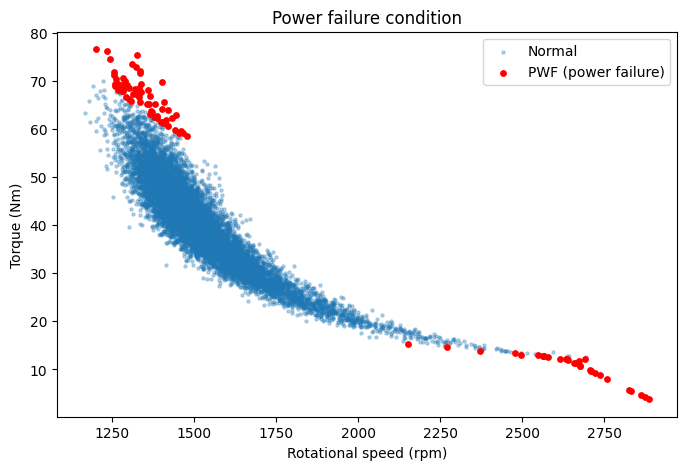

In [25]:
normal = df[df['PWF'] == 0]
fail = df[df['PWF'] == 1]

plt.figure(figsize=(8, 5))
plt.scatter(normal['Rotational speed [rpm]'], normal['Torque [Nm]'], s=5, alpha=0.3, label='Normal')
plt.scatter(fail['Rotational speed [rpm]'], fail['Torque [Nm]'], s=15, c='red', label='PWF (power failure)')
plt.xlabel('Rotational speed (rpm)')
plt.ylabel('Torque (Nm)')
plt.title('Power failure condition')
plt.legend()
plt.show()

### 3-4. 과부하 고장 (OSF)
- 공구를 오래 쓰고 토크가 큰 영역에서 발생하며, 경계가 **곡선** 형태
- 공구가 많이 닳을수록 더 낮은 토크에서도 고장 → **마모 × 토크**가 한계를 넘을 때 발생
- 같은 조건에서도 고장 여부가 갈리는 점이 있어, 제품 등급별로 한계가 다른 것으로 보인다

→ 부하를 많이 받는 설비는 **교체 주기를 더 짧게** 가져가야 한다.

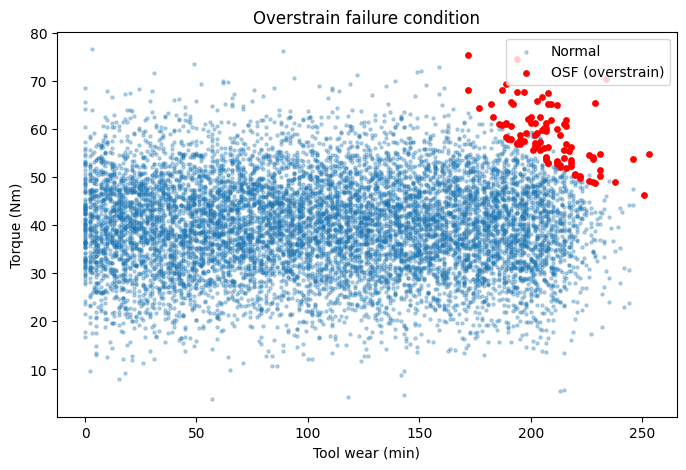

In [26]:
normal = df[df['OSF'] == 0]
fail = df[df['OSF'] == 1]

plt.figure(figsize=(8, 5))
plt.scatter(normal['Tool wear [min]'], normal['Torque [Nm]'], s=5, alpha=0.3, label='Normal')
plt.scatter(fail['Tool wear [min]'], fail['Torque [Nm]'], s=15, c='red', label='OSF (overstrain)')
plt.xlabel('Tool wear (min)')
plt.ylabel('Torque (Nm)')
plt.title('Overstrain failure condition')
plt.legend()
plt.show()

### 3단계 정리

| 고장 | 원인 | 주기 PM으로 대응 |
|---|---|---|
| 공구 마모 (46) | 사용 시간 200분 이후 | 가능 |
| 열 방출 (115) | 온도 차이 작음 + 회전 느림 | 어려움 |
| 전력 (95) | 전력 과다 또는 부족 | 어려움 |
| 과부하 (98) | 마모 × 토크 한계 초과 | 시간과 부하를 함께 봐야 함 |
| 무작위 (19) | 예측 불가 | 어려움 |

**가설 확인:** 사용 시간만으로 막을 수 있는 고장은 일부이고, 대부분은 **상태 데이터의 조합**을 봐야 잡을 수 있다.

## 4. 고장 예측 모델

3단계에서 찾은 원인을 변수로 만들어 모델에 추가했다.
- `temp_diff` = 공정 온도 − 주변 온도 (열 방출)
- `power` = 토크 × 회전 속도 (전력)
- `strain` = 공구 사용 시간 × 토크 (과부하)

모델은 결과를 사람이 읽을 수 있는 **결정 나무**(깊이 5)를 사용했고, 데이터의 70%로 학습하고 30%로 평가했다.
고장 유형 열(TWF 등)은 정답 정보라서 입력에서 제외했다.

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report

# 3단계에서 찾은 원인을 숫자로 만들기
df['power'] = df['Torque [Nm]'] * df['Rotational speed [rpm]'] * 2 * 3.1416 / 60
df['strain'] = df['Tool wear [min]'] * df['Torque [Nm]']
df['type_num'] = df['Type'].map({'L': 0, 'M': 1, 'H': 2})

features = ['type_num', 'Air temperature [K]', 'Process temperature [K]',
            'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]',
            'temp_diff', 'power', 'strain']

X = df[features]
y = df['Machine failure']

# 70%로 학습, 30%로 시험
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

model = DecisionTreeClassifier(max_depth=5, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))

[[2894    4]
 [  15   87]]
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      2898
           1       0.96      0.85      0.90       102

    accuracy                           0.99      3000
   macro avg       0.98      0.93      0.95      3000
weighted avg       0.99      0.99      0.99      3000



**결과 (시험 데이터 3,000건)**
- 실제 고장 102건 중 **87건 감지 (recall 85%)**
- 잘못된 경보 4건 (precision 96%)
- 놓친 고장 15건 → 무작위 고장처럼 원래 예측이 어려운 경우가 섞여 있을 것으로 보인다

### 비교: 원인 변수를 빼면?
3단계에서 만든 변수(temp_diff, power, strain)를 빼고, 원래 데이터만으로 같은 모델을 학습해 비교했다.

In [28]:
# 원래 데이터만 사용 (네가 만든 3가지 빼기)
base = ['type_num', 'Air temperature [K]', 'Process temperature [K]',
        'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

model_base = DecisionTreeClassifier(max_depth=5, random_state=42)
model_base.fit(X_train[base], y_train)
pred_base = model_base.predict(X_test[base])

print(confusion_matrix(y_test, pred_base))
print(classification_report(y_test, pred_base))

[[2881   17]
 [  62   40]]
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      2898
           1       0.70      0.39      0.50       102

    accuracy                           0.97      3000
   macro avg       0.84      0.69      0.74      3000
weighted avg       0.97      0.97      0.97      3000



| | 원래 변수만 | 원인 변수 추가 |
|---|---|---|
| 고장 감지율 (recall) | 39% | **85%** |
| 잘못된 경보 | 17건 | **4건** |
| 정확도 | 97% | 99% |

**현장 관점에서 찾은 원인을 변수로 추가하자 고장 감지율이 두 배 이상 올랐다.**

## 배운 점과 한계
- 원래 변수만 쓴 모델도 정확도는 97%였지만 고장의 60% 이상을 놓쳤다. **정확도만 보면 성능을 잘못 판단할 수 있다.**
- 고장을 놓쳐 설비가 멈추는 비용이 잘못된 경보로 점검하는 비용보다 크므로, 실제로 쓴다면 경보를 조금 늘리더라도 감지율을 높이는 쪽으로 조정하는 것이 맞다고 본다.
- 실제 공장 데이터를 바탕으로 만든 **합성 데이터**라 결과를 그대로 현장에 적용하긴 어렵다. 다만 "주기 기반 PM을 상태 데이터로 보완할 수 있다"는 방향은 확인할 수 있었다.